In [1]:
import sys
print(sys.executable)

from ultralytics import YOLO
print("Ultralytics imported successfully!")

d:\college RBU\projects\5_sem_DIP_TA_project\Railway-Platform-Safety-main\venv\Scripts\python.exe
Ultralytics imported successfully!


In [2]:
from ultralytics import YOLO

model = YOLO("models/railway_segmentation.pt")

print("Model loaded successfully!")

Model loaded successfully!


In [3]:
results = model("models/train.jpeg")

print("Detection completed!")


image 1/1 d:\college RBU\projects\5_sem_DIP_TA_project\Railway-Platform-Safety-main\models\train.jpeg: 288x416 3 rail_tracks, 221.4ms
Speed: 23.9ms preprocess, 221.4ms inference, 28.2ms postprocess per image at shape (1, 3, 288, 416)
Detection completed!


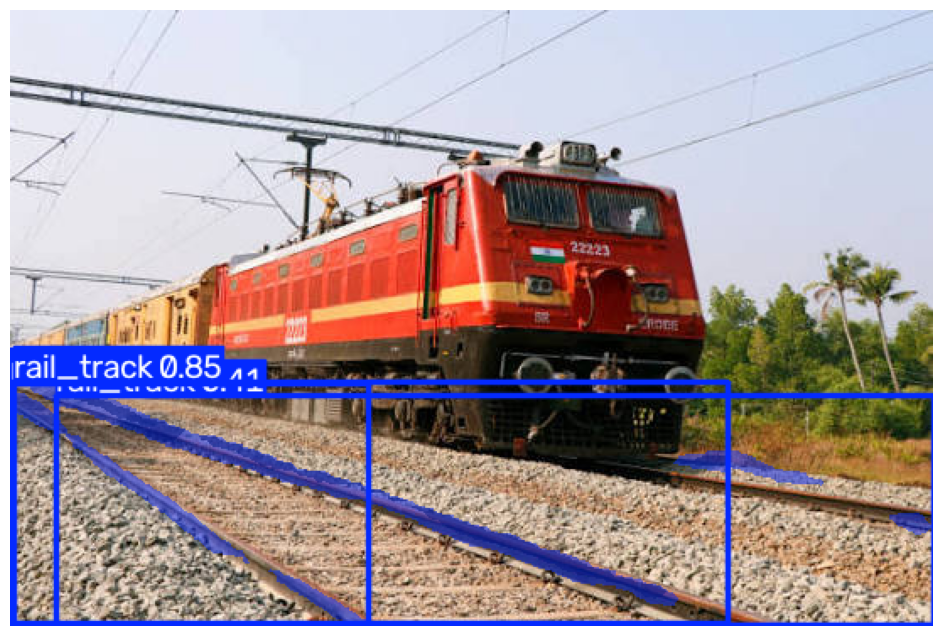

In [4]:
import matplotlib.pyplot as plt

# Get the image with detections drawn on it
annotated_image = results[0].plot()

# Display it inside VS Code Notebook
plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.show()

In [ ]:
video_results = model.predict(
    source="models/test_video.mp4",
    save=True,
    show=False
)

print("Video detection completed!")

In [6]:
from ultralytics import YOLO

person_model = YOLO("yolov8n.pt")

print("Person detection model loaded!")

Person detection model loaded!


In [7]:
person_results = person_model("models/person.jpeg")

print("Person detection completed!")


image 1/1 d:\college RBU\projects\5_sem_DIP_TA_project\Railway-Platform-Safety-main\models\person.jpeg: 480x640 2 persons, 1 train, 256.4ms
Speed: 18.7ms preprocess, 256.4ms inference, 29.2ms postprocess per image at shape (1, 3, 480, 640)
Person detection completed!


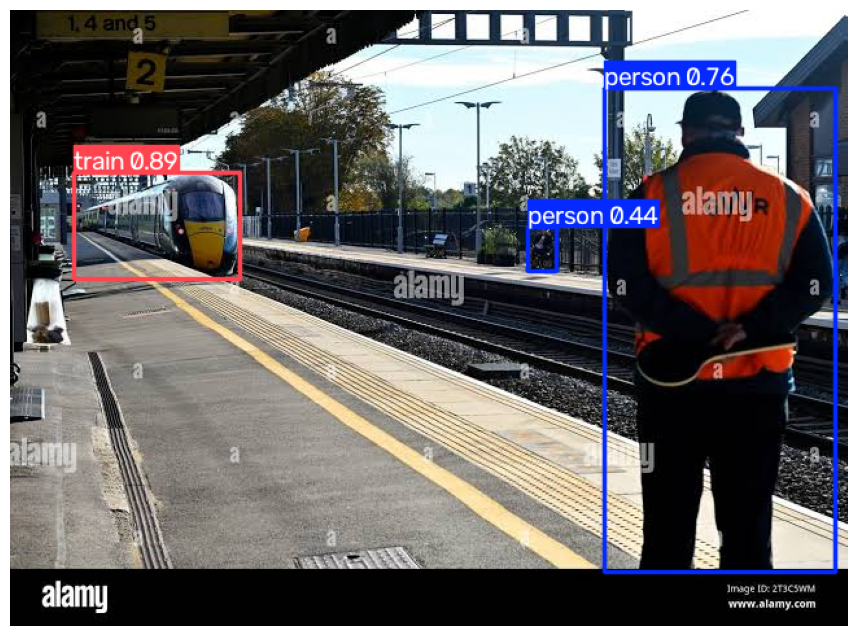

In [8]:
import matplotlib.pyplot as plt

person_image = person_results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(person_image[:, :, ::-1])
plt.axis("off")
plt.show()

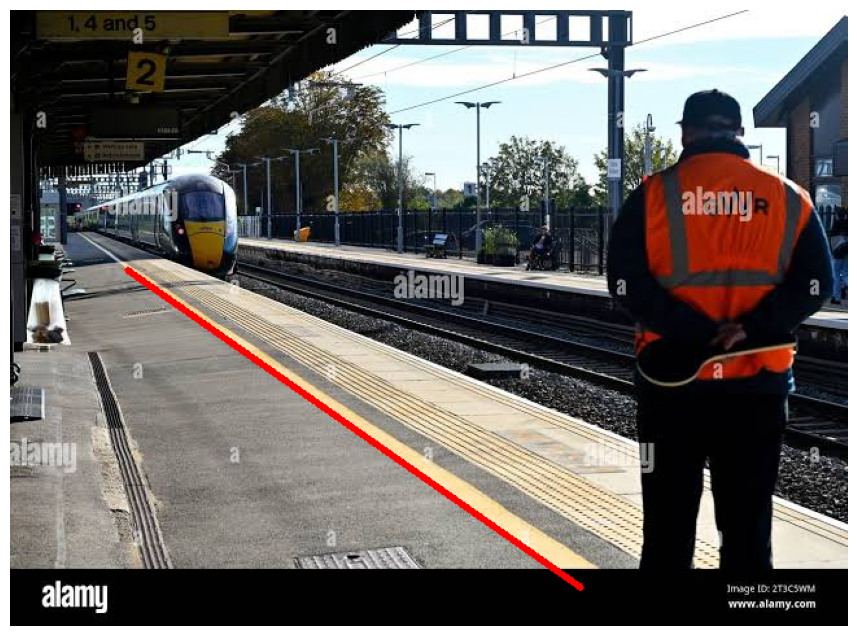

In [31]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("models/person.jpeg")

# Safety line coordinates
# Approximate points based on your image
x1, y1 = 90, 200
x2, y2 = 440, 445

# Draw safety line
cv2.line(img, (x1, y1), (x2, y2), (0, 0, 255), 4)

# Display
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [32]:
results = person_model("models/person.jpeg")

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = person_model.names[class_id]
    confidence = float(box.conf[0])

    if class_name == "person":
        x1, y1, x2, y2 = map(int, box.xyxy[0])

        # Bottom-center point of person
        center_x = (x1 + x2) // 2
        bottom_y = y2

        print("Person detected")
        print("Bounding box:", x1, y1, x2, y2)
        print("Bottom-center:", center_x, bottom_y)
        print("Confidence:", round(confidence, 2))


image 1/1 d:\college RBU\projects\5_sem_DIP_TA_project\Railway-Platform-Safety-main\models\person.jpeg: 480x640 2 persons, 1 train, 180.1ms
Speed: 16.7ms preprocess, 180.1ms inference, 3.2ms postprocess per image at shape (1, 3, 480, 640)
Person detected
Bounding box: 458 60 636 433
Bottom-center: 547 433
Confidence: 0.76
Person detected
Bounding box: 399 167 421 201
Bottom-center: 410 201
Confidence: 0.44


In [33]:
def line_side(px, py, x1, y1, x2, y2):
    return (x2 - x1) * (py - y1) - (y2 - y1) * (px - x1)

In [35]:
safety_x1, safety_y1 = 90, 200
safety_x2, safety_y2 = 440, 445

point_side = line_side(
    center_x,
    bottom_y,
    safety_x1,
    safety_y1,
    safety_x2,
    safety_y2
)

print("Point side value:", point_side)

Point side value: -78050


In [36]:
if point_side < 0:
    status = "PERSON ON PLATFORM / SAFE"
else:
    status = "WARNING: PERSON CROSSED SAFETY LINE"

print(status)

PERSON ON PLATFORM / SAFE


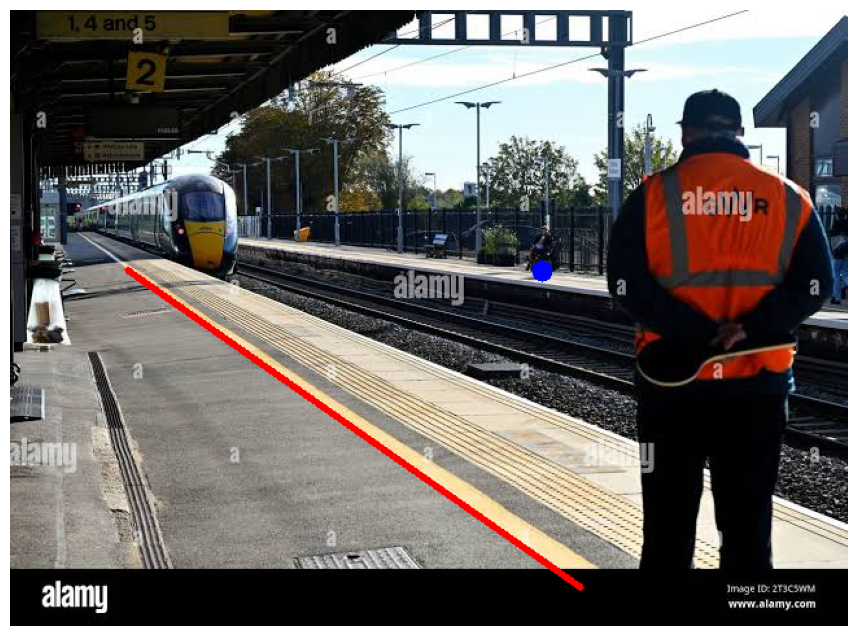

In [37]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("models/person.jpeg")

# Draw safety line
cv2.line(
    img,
    (safety_x1, safety_y1),
    (safety_x2, safety_y2),
    (0, 0, 255),
    4
)

# Draw person's bottom-center
cv2.circle(
    img,
    (center_x, bottom_y),
    8,
    (255, 0, 0),
    -1
)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


image 1/1 d:\college RBU\projects\5_sem_DIP_TA_project\Railway-Platform-Safety-main\models\person.jpeg: 480x640 2 persons, 1 train, 133.8ms
Speed: 10.7ms preprocess, 133.8ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 640)


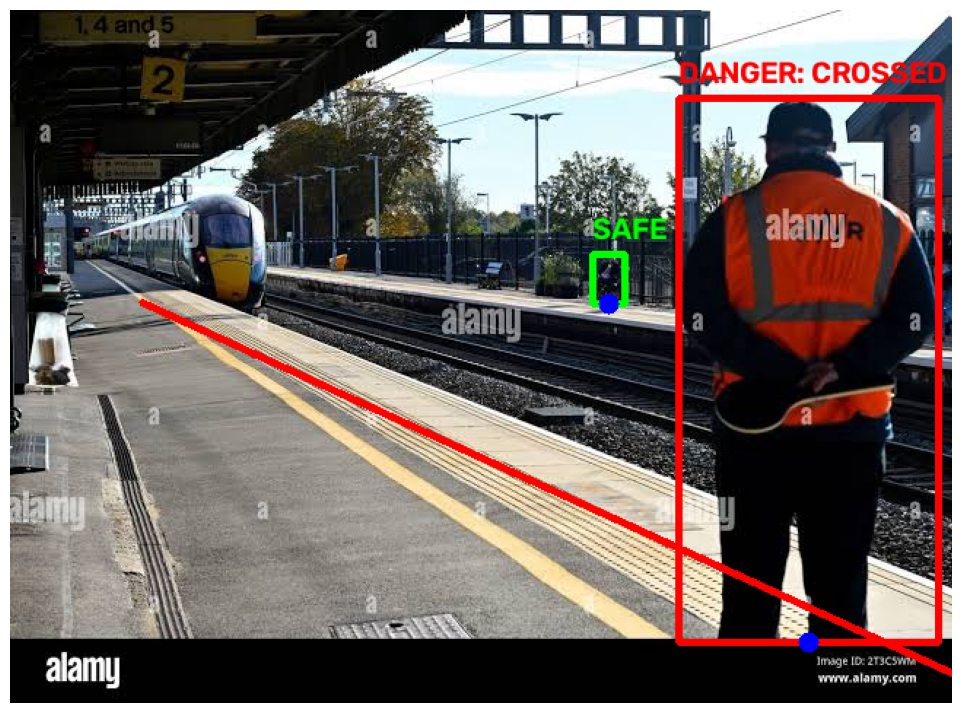

In [38]:
import cv2
import matplotlib.pyplot as plt

# Run person detection
results = person_model("models/person.jpeg")

# Load original image
img = cv2.imread("models/person.jpeg")

# Safety line coordinates
safety_x1, safety_y1 = 90, 200
safety_x2, safety_y2 = 645, 454

# Draw safety line
cv2.line(
    img,
    (safety_x1, safety_y1),
    (safety_x2, safety_y2),
    (0, 0, 255),
    4
)

# Check every detected person
for box in results[0].boxes:

    class_id = int(box.cls[0])
    class_name = person_model.names[class_id]

    if class_name == "person":

        bx1, by1, bx2, by2 = map(int, box.xyxy[0])

        # Bottom-center of person
        person_x = (bx1 + bx2) // 2
        person_y = by2

        # Determine which side of safety line
        side = (
            (safety_x2 - safety_x1) * (person_y - safety_y1)
            - (safety_y2 - safety_y1) * (person_x - safety_x1)
        )

        # Current assumption:
        # Negative = platform/safe side
        # Positive = track/danger side
        if side < 0:
            status = "SAFE"
            text_color = (0, 255, 0)
        else:
            status = "DANGER: CROSSED SAFETY LINE"
            text_color = (0, 0, 255)

        # Draw bounding box
        cv2.rectangle(
            img,
            (bx1, by1),
            (bx2, by2),
            text_color,
            3
        )

        # Draw bottom-center point
        cv2.circle(
            img,
            (person_x, person_y),
            7,
            (255, 0, 0),
            -1
        )

        # Display status
        cv2.putText(
            img,
            status,
            (bx1, max(by1 - 10, 25)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            text_color,
            2
        )

# Display result
plt.figure(figsize=(14, 9))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


image 1/1 d:\college RBU\projects\5_sem_DIP_TA_project\Railway-Platform-Safety-main\models\person2.jpeg: 640x384 1 person, 1 train, 118.8ms
Speed: 8.5ms preprocess, 118.8ms inference, 3.7ms postprocess per image at shape (1, 3, 640, 384)


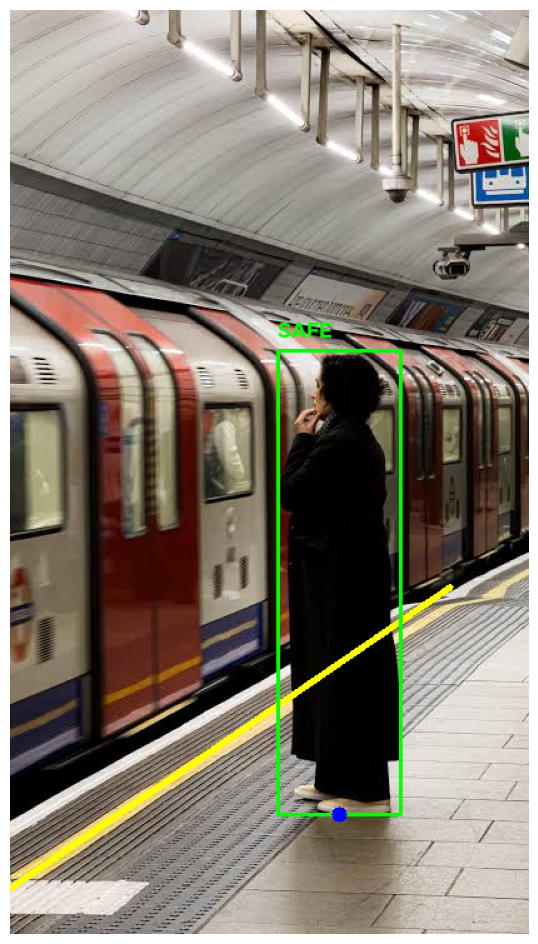

In [63]:
import cv2
import matplotlib.pyplot as plt

# Load original image to get actual dimensions
img = cv2.imread("models/person2.jpeg")
h, w, _ = img.shape

# Run person detection
results = person_model("models/person2.jpeg")

# Safety line coordinates aligned to yellow line
safety_x1, safety_y1 = 0, int(h * 0.95)      # (0, 910)
safety_x2, safety_y2 = int(w * 0.85), int(h * 0.625) # (297, 600)

# Draw safety line
cv2.line(
    img,
    (safety_x1, safety_y1),
    (safety_x2, safety_y2),
    (0, 255, 255), # Yellow color in BGR
    3
)

# Check every detected person
for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = person_model.names[class_id]

    if class_name == "person":
        bx1, by1, bx2, by2 = map(int, box.xyxy[0])

        # Bottom-center of person
        person_x = (bx1 + bx2) // 2
        person_y = by2

        # 2D Cross Product / Line side determinant
        side = (
            (safety_x2 - safety_x1) * (person_y - safety_y1)
            - (safety_y2 - safety_y1) * (person_x - safety_x1)
        )

        # Fixed orientation check for vector pointing from (0, 910) to (300, 600):
        # side > 0 corresponds to the platform side (Right of vector)
        if side > 0:
            status = "SAFE"
            text_color = (0, 255, 0)
        else:
            status = "DANGER: CROSSED SAFETY LINE"
            text_color = (0, 0, 255)

        # Draw bounding box
        cv2.rectangle(img, (bx1, by1), (bx2, by2), text_color, 2)

        # Draw bottom-center point
        cv2.circle(img, (person_x, person_y), 6, (255, 0, 0), -1)

        # Display status
        cv2.putText(
            img,
            status,
            (bx1, max(by1 - 10, 25)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            text_color,
            2
        )

# Display result
plt.figure(figsize=(10, 12))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()